# Day 28 — Gradient Boosting, XGBoost, and Controlled Model Tuning

**Objective:** Build a baseline, implement boosting by hand, compare Random Forest and XGBoost, tune boosting settings, compare libraries, and interpret feature importance.

**Data handling:** A stratified 80/20 split with `random_state=42` is made once. Age group medians and the fare median are learned from the training data only, then applied to both train and test data to avoid preprocessing leakage. The test set is reused for the required experiments in this teaching task; for real model selection, use a separate validation set and reserve the test set for final evaluation.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,accuracy_score, roc_auc_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.inspection import permutation_importance
from sklearn.inspection import PartialDependenceDisplay

In [2]:
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)

Dataset shape: (891, 15)


In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 116.9 KB


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Normalize column names
df.columns = df.columns.str.strip().str.lower()
print("Columns:", df.columns.tolist())

Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [8]:
# Check the columns required for this task
required_columns = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]

In [9]:
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Keep only required source columns; do not create an embarked feature.
df = df[required_columns].dropna(subset=["survived"]).copy()
print("Rows available for modeling:", len(df))

Rows available for modeling: 891


In [10]:
# Convert sex to a numeric feature before splitting
df["sex_male"] = (df["sex"].str.strip().str.lower() == "male").astype(int)

features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

X_raw = df[features].copy()
y = df[target].astype(int)

In [11]:
# The overall age and fare medians will be learned from training data only.
# This avoids using information from the test set during preprocessing.

In [12]:
# Split once, stratifying by survival and keeping random_state=42.
X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 712
Test rows: 179


In [13]:
# Learn age medians from the training set, grouped by passenger class and sex.
train_age_group_medians = X_train.groupby(
    ["pclass", "sex_male"]
)["age"].median()

overall_age_median = X_train["age"].median()
fare_median = X_train["fare"].median()

def impute_features(frame):
    frame = frame.copy()

    # Look up the training median for each pclass/sex group.
    group_medians = [
        train_age_group_medians.get((pclass, sex_male), np.nan)
        for pclass, sex_male in zip(frame["pclass"], frame["sex_male"])
    ]
    group_medians = pd.Series(group_medians, index=frame.index)

    frame["age"] = frame["age"].fillna(group_medians)
    frame["age"] = frame["age"].fillna(overall_age_median)
    frame["fare"] = frame["fare"].fillna(fare_median)

    return frame

X_train = impute_features(X_train)
X_test = impute_features(X_test)

print("Missing values in training features:")
display(X_train.isnull().sum())
print("Missing values in test features:")
display(X_test.isnull().sum())

Missing values in training features:


pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Missing values in test features:


pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

In [14]:
# Check that the feature columns match the task sheet.
print("Features:", features)
print("Target:", target)

Features: ['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']
Target: survived


In [15]:
# Verify that preprocessing left no missing values.
assert X_train.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0
assert list(X_train.columns) == features
assert list(X_test.columns) == features

print("Preprocessing checks passed.")

Preprocessing checks passed.


In [16]:
print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

Training feature shape: (712, 6)
Test feature shape: (179, 6)
Training target shape: (712,)
Test target shape: (179,)


In [17]:
# The split was already created before imputing missing values.
# X_train, X_test, y_train, and y_test are reused for every task.

In [18]:
# Confirm class balance after the stratified split.
print("Training survival rate:", round(y_train.mean(), 4))
print("Test survival rate:", round(y_test.mean(), 4))

Training survival rate: 0.3834
Test survival rate: 0.3855


In [19]:
print("The same stratified 80/20 split will be reused for all model comparisons.")

The same stratified 80/20 split will be reused for all model comparisons.


# Task-1

In [20]:
# Calculate the mean survival value from the training data
baseline = y_train.mean()

# Predict the same value for every training passenger
y_pred_baseline = np.full(len(y_train), baseline)

print("Baseline prediction:", baseline)

Baseline prediction: 0.38342696629213485


In [21]:
# Residual = Actual value - Predicted value
residuals = y_train.to_numpy() - y_pred_baseline

print("First 10 residuals:")
print(residuals[:10])

First 10 residuals:
[ 0.61657303 -0.38342697 -0.38342697  0.61657303  0.61657303 -0.38342697
  0.61657303 -0.38342697  0.61657303 -0.38342697]


In [22]:
baseline_mse = mean_squared_error(
    y_train,
    y_pred_baseline
)

print("Baseline Mean Squared Error (MSE):", baseline_mse)

Baseline Mean Squared Error (MSE): 0.2364107278121449


In [23]:
results = pd.DataFrame({
    "Actual_Survived": y_train.to_numpy(),
    "Baseline_Prediction": y_pred_baseline,
    "Residual": residuals
})

results.head(10)


,Actual_Survived,Baseline_Prediction,Residual
0,1,0.383427,0.616573
1,0,0.383427,-0.383427
2,0,0.383427,-0.383427
3,1,0.383427,0.616573
4,1,0.383427,0.616573
5,0,0.383427,-0.383427
6,1,0.383427,0.616573
7,0,0.383427,-0.383427
8,1,0.383427,0.616573
9,0,0.383427,-0.383427


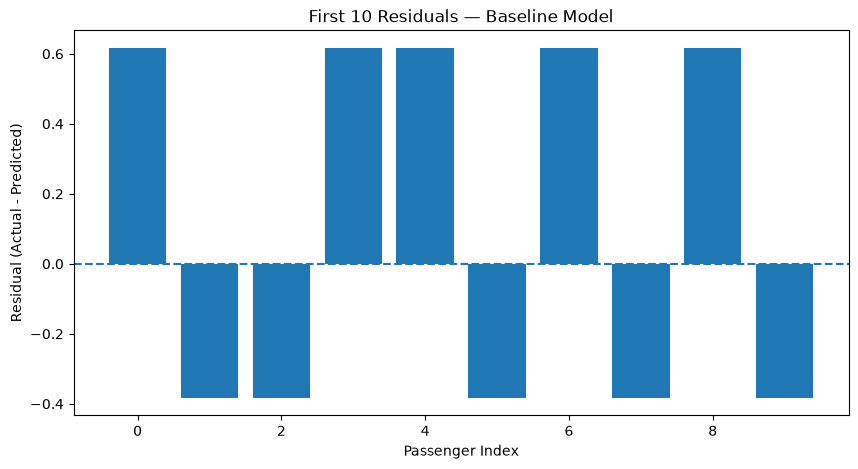

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(10),
    residuals[:10]
)

plt.axhline(y=0, linestyle="--")

plt.title("First 10 Residuals — Baseline Model")
plt.xlabel("Passenger Index")
plt.ylabel("Residual (Actual - Predicted)")

plt.show()


The baseline prediction is the mean of `y_train`, so every training passenger receives the same predicted probability.

The residual is:

`Residual = Actual - Predicted`

Because the baseline mean is between 0 and 1:
- For a passenger who survived (`actual = 1`), the residual is positive.
- For a passenger who did not survive (`actual = 0`), the residual is negative.

A positive residual means the prediction needs to move upward; a negative residual means it needs to move downward. The baseline MSE measures the average squared error of this constant prediction.

# Task-2

In [25]:
# Set the learning rate
learning_rate = 0.3

# Set the number of boosting rounds
n_rounds = 30

# Start with the mean survival value
baseline = y_train.mean()

# Give every training passenger the same initial prediction
prediction = np.full(len(y_train), baseline)

# Store the trained trees
trees = []

# Store training MSE after each round
train_mse_history = []

In [26]:
print("Learning rate:", learning_rate)
print("Number of rounds:", n_rounds)
print("Initial prediction:", baseline)

Learning rate: 0.3
Number of rounds: 30
Initial prediction: 0.38342696629213485


In [27]:
for round_num in range(n_rounds):

    # Calculate the remaining errors
    residual = y_train.to_numpy() - prediction

    # Train a small tree to predict the residuals
    tree = DecisionTreeRegressor(max_depth=2)
    tree.fit(X_train, residual)

    # Predict the correction from the tree
    correction = tree.predict(X_train)

    # Update the current predictions
    prediction += learning_rate * correction

    # Save the trained tree
    trees.append(tree)

    # Calculate and store the training MSE
    mse = mean_squared_error(y_train, prediction)
    train_mse_history.append(mse)

    print(f"Round {round_num + 1}: Training MSE = {mse:.4f}")


Round 1: Training MSE = 0.1858
Round 2: Training MSE = 0.1605
Round 3: Training MSE = 0.1472
Round 4: Training MSE = 0.1398
Round 5: Training MSE = 0.1349
Round 6: Training MSE = 0.1313
Round 7: Training MSE = 0.1269
Round 8: Training MSE = 0.1244
Round 9: Training MSE = 0.1222
Round 10: Training MSE = 0.1209
Round 11: Training MSE = 0.1188
Round 12: Training MSE = 0.1177
Round 13: Training MSE = 0.1168
Round 14: Training MSE = 0.1159
Round 15: Training MSE = 0.1144
Round 16: Training MSE = 0.1132
Round 17: Training MSE = 0.1121
Round 18: Training MSE = 0.1114
Round 19: Training MSE = 0.1110
Round 20: Training MSE = 0.1106
Round 21: Training MSE = 0.1099
Round 22: Training MSE = 0.1094
Round 23: Training MSE = 0.1087
Round 24: Training MSE = 0.1084
Round 25: Training MSE = 0.1072
Round 26: Training MSE = 0.1066
Round 27: Training MSE = 0.1064
Round 28: Training MSE = 0.1054
Round 29: Training MSE = 0.1051
Round 30: Training MSE = 0.1044


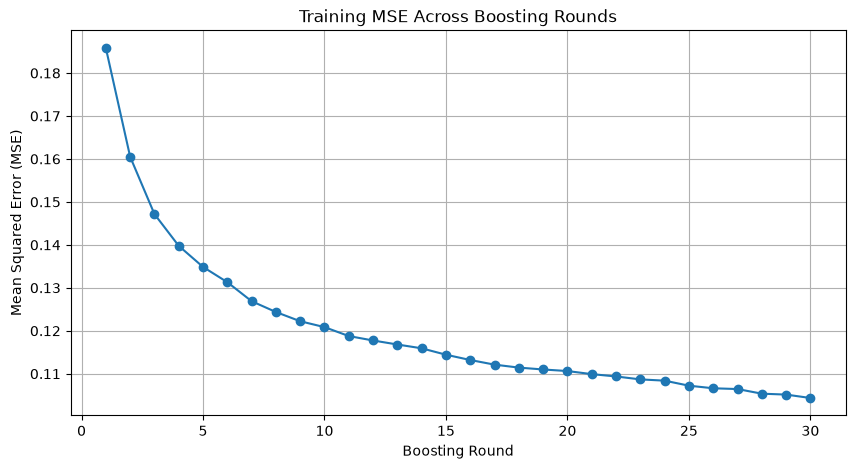

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_rounds + 1),
    train_mse_history,
    marker="o"
)

plt.title("Training MSE Across Boosting Rounds")
plt.xlabel("Boosting Round")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True)

plt.show()


In [29]:
def predict_boosting(X):
    # Start with the same baseline prediction
    predictions = np.full(len(X), baseline)

    # Apply each tree in the same order
    for tree in trees:
        predictions += learning_rate * tree.predict(X)

    return predictions

In [30]:
# Predict survival scores for test passengers
y_test_scores = predict_boosting(X_test)

# Convert scores to binary predictions using 0.5
y_test_pred = (y_test_scores >= 0.5).astype(int)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

# Calculate ROC-AUC using continuous prediction scores
test_auc = roc_auc_score(y_test, y_test_scores)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")


Test Accuracy: 0.7933
Test ROC-AUC: 0.8298


- I implemented a simple Gradient Boosting model using DecisionTreeRegressor without using a boosting library.

- The model starts with the mean of the training target and trains 30 shallow trees with max_depth=2. Each tree learns the residuals left by the current predictions, and its correction is multiplied by a learning rate of 0.3.

- The training MSE generally decreases because each new tree attempts to correct the remaining errors. Shallow trees can combine into a stronger model because each tree learns a small part of the remaining error.

- The test accuracy and ROC-AUC measure how well the model performs on unseen passengers. Training performance alone is not enough to determine whether the model generalizes well.


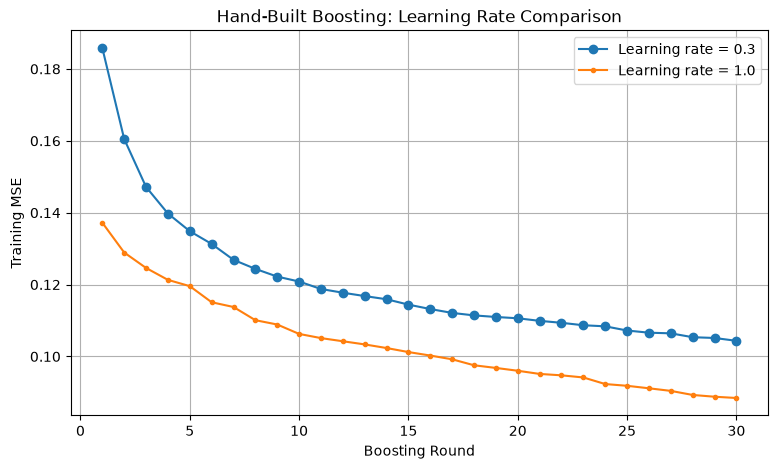

Final training MSE, learning_rate=0.3: 0.1044
Final training MSE, learning_rate=1.0: 0.0884


In [31]:

# Task 2 experiment: compare learning_rate=1.0 with the original 0.3.
# Use separate variable names so the original 0.3 model remains unchanged.
learning_rate_1 = 1.0
prediction_lr1 = np.full(len(y_train), y_train.mean())
trees_lr1 = []
train_mse_lr1 = []

for round_num in range(30):
    residual_lr1 = y_train.to_numpy() - prediction_lr1

    tree_lr1 = DecisionTreeRegressor(max_depth=2, random_state=42)
    tree_lr1.fit(X_train, residual_lr1)

    prediction_lr1 += learning_rate_1 * tree_lr1.predict(X_train)
    trees_lr1.append(tree_lr1)

    train_mse_lr1.append(mean_squared_error(y_train, prediction_lr1))

plt.figure(figsize=(9, 5))
plt.plot(range(1, 31), train_mse_history, marker="o", label="Learning rate = 0.3")
plt.plot(range(1, 31), train_mse_lr1, marker=".", label="Learning rate = 1.0")
plt.title("Hand-Built Boosting: Learning Rate Comparison")
plt.xlabel("Boosting Round")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True)
plt.show()

print("Final training MSE, learning_rate=0.3:", round(train_mse_history[-1], 4))
print("Final training MSE, learning_rate=1.0:", round(train_mse_lr1[-1], 4))



**Learning-rate experiment:** A learning rate of 1.0 applies each tree's full correction, while 0.3 applies only 30% of it. Compare the two MSE curves: a larger learning rate may reduce training error faster, but it can also make updates too aggressive and may generalize less well. The curve, rather than an assumption, should support your conclusion.


# Task-3

In [32]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [33]:
# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

# Train the model
xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [34]:
# Random Forest predictions
rf_train_scores = rf_model.predict_proba(X_train)[:, 1]
rf_test_scores = rf_model.predict_proba(X_test)[:, 1]
rf_test_pred = rf_model.predict(X_test)

# XGBoost predictions
xgb_train_scores = xgb_model.predict_proba(X_train)[:, 1]
xgb_test_scores = xgb_model.predict_proba(X_test)[:, 1]
xgb_test_pred = xgb_model.predict(X_test)

# Calculate metrics
rf_train_auc = roc_auc_score(y_train, rf_train_scores)
rf_test_auc = roc_auc_score(y_test, rf_test_scores)
rf_accuracy = accuracy_score(y_test, rf_test_pred)

xgb_train_auc = roc_auc_score(y_train, xgb_train_scores)
xgb_test_auc = roc_auc_score(y_test, xgb_test_scores)
xgb_accuracy = accuracy_score(y_test, xgb_test_pred)

# Calculate train-test AUC gaps
rf_gap = rf_train_auc - rf_test_auc
xgb_gap = xgb_train_auc - xgb_test_auc

print("Random Forest evaluation completed!")
print("XGBoost evaluation completed!")


Random Forest evaluation completed!
XGBoost evaluation completed!


In [35]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Training ROC-AUC": [rf_train_auc, xgb_train_auc],
    "Test Accuracy": [rf_accuracy, xgb_accuracy],
    "Test ROC-AUC": [rf_test_auc, xgb_test_auc],
    "Train-Test AUC Gap": [rf_gap, xgb_gap]
})

display(comparison.round(4))

,Model,Training ROC-AUC,Test Accuracy,Test ROC-AUC,Train-Test AUC Gap
0,Random Forest,0.9978,0.8212,0.8422,0.1557
1,XGBoost,0.9700,0.8045,0.8202,0.1498


- Random Forest uses bagging: trees are trained independently and their predictions are combined. XGBoost uses boosting: trees are added sequentially to correct remaining errors.
- Use the comparison table above to identify the model with the higher test ROC-AUC and the model with the larger train-test AUC gap.
- A larger gap can indicate overfitting because training performance is substantially stronger than test performance. A good test score is useful, but a large gap suggests the model may be relying on patterns that do not generalize.

# Task-4

In [36]:
# Create an XGBoost model with early stopping
early_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42
)

print("Early-stopping model created!")


Early-stopping model created!


In [37]:
early_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_test, y_test)
    ],
    verbose=False
)

print("Early-stopping training completed!")


Early-stopping training completed!


In [38]:
# Get the best boosting iteration
best_iteration = early_model.best_iteration

# Predict survival probabilities
early_test_scores = early_model.predict_proba(X_test)[:, 1]

# Calculate test ROC-AUC
early_test_auc = roc_auc_score(y_test, early_test_scores)

# Compare with the 300-tree XGBoost model from Task 3
print("Best iteration:", best_iteration)
print(f"Early-stopping Test ROC-AUC: {early_test_auc:.4f}")
print(f"300-tree XGBoost Test ROC-AUC: {xgb_test_auc:.4f}")

difference = early_test_auc - xgb_test_auc
print(f"ROC-AUC difference: {difference:+.4f}")


Best iteration: 30
Early-stopping Test ROC-AUC: 0.8374
300-tree XGBoost Test ROC-AUC: 0.8202
ROC-AUC difference: +0.0173


In [39]:
eval_results = early_model.evals_result()

train_logloss = eval_results["validation_0"]["logloss"]
validation_logloss = eval_results["validation_1"]["logloss"]

print("Training rounds completed:", len(train_logloss))
print("Best iteration:", best_iteration)


Training rounds completed: 61
Best iteration: 30


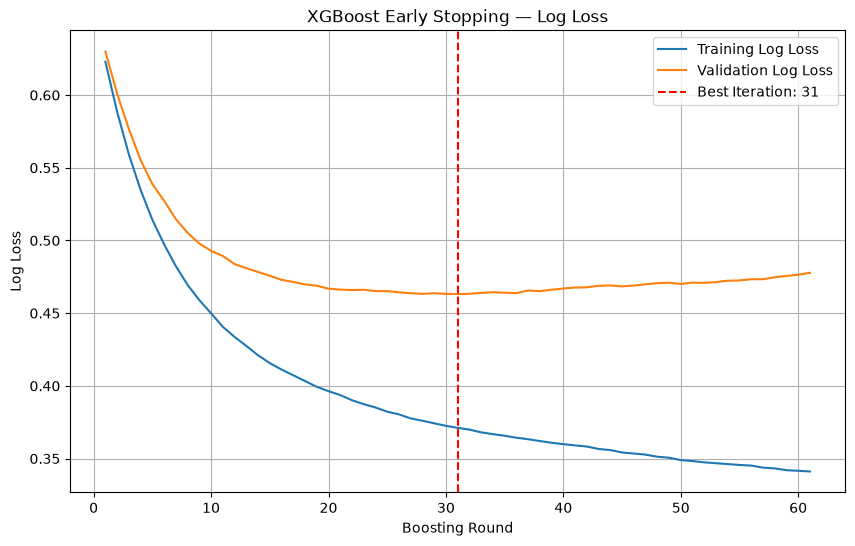

In [40]:
rounds = range(1, len(train_logloss) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    rounds,
    train_logloss,
    label="Training Log Loss"
)

plt.plot(
    rounds,
    validation_logloss,
    label="Validation Log Loss"
)

# XGBoost uses a zero-based best_iteration index
plt.axvline(
    x=best_iteration + 1,
    color="red",
    linestyle="--",
    label=f"Best Iteration: {best_iteration + 1}"
)

plt.title("XGBoost Early Stopping — Log Loss")
plt.xlabel("Boosting Round")
plt.ylabel("Log Loss")
plt.legend()
plt.grid(True)

plt.show()


- Early stopping monitors validation log loss and stops after it has failed to improve for 30 rounds.
- The code above prints the best iteration and the test ROC-AUC for both the early-stopped model and the 300-tree model.
- A higher or lower test ROC-AUC is possible because the models use different numbers of trees; early stopping optimizes validation log loss, not ROC-AUC.
- In the plot, training log loss generally decreases as trees are added. If validation log loss starts increasing while training loss continues decreasing, that divergence is evidence of overfitting.
- **Limitation:** This teaching task uses the test set as the early-stopping evaluation set, as specified by the task sheet. In real projects, use a separate validation set and keep the test set untouched until final evaluation.

# Task-5

In [41]:
# Required learning-rate and tree-count combinations
settings = [
    (0.30, 50),
    (0.10, 150),
    (0.05, 300),
    (0.01, 1500)
]

results_task5 = []

for learning_rate, n_estimators in settings:

    # Create the model
    model = XGBClassifier(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict survival probabilities
    y_scores = model.predict_proba(X_test)[:, 1]

    # Calculate test ROC-AUC
    test_auc = roc_auc_score(y_test, y_scores)

    # Save the results
    results_task5.append({
        "Learning Rate": learning_rate,
        "Number of Trees": n_estimators,
        "Test ROC-AUC": test_auc
    })

# Display comparison table
paired_results = pd.DataFrame(results_task5)

display(paired_results.round(4))


,Learning Rate,Number of Trees,Test ROC-AUC
0,0.30,50,0.8130
1,0.10,150,0.8218
2,0.05,300,0.8148
3,0.01,1500,0.8185


In [42]:
# Deliberately mismatched settings
broken_settings = [
    (0.01, 50),
    (0.30, 1500)
]

broken_results = []

for learning_rate, n_estimators in broken_settings:

    model = XGBClassifier(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )

    model.fit(X_train, y_train)

    y_scores = model.predict_proba(X_test)[:, 1]

    test_auc = roc_auc_score(y_test, y_scores)

    broken_results.append({
        "Learning Rate": learning_rate,
        "Number of Trees": n_estimators,
        "Test ROC-AUC": test_auc
    })

broken_table = pd.DataFrame(broken_results)

display(broken_table.round(4))


,Learning Rate,Number of Trees,Test ROC-AUC
0,0.01,50,0.8350
1,0.30,1500,0.8338


In [43]:
all_results_task5 = pd.concat(
    [paired_results, broken_table],
    ignore_index=True
)

display(all_results_task5.round(4))

,Learning Rate,Number of Trees,Test ROC-AUC
0,0.30,50,0.8130
1,0.10,150,0.8218
2,0.05,300,0.8148
3,0.01,1500,0.8185
4,0.01,50,0.8350
5,0.30,1500,0.8338


- The learning rate controls how much each tree contributes; `n_estimators` controls the number of boosting rounds.
- In this run, the highest measured test ROC-AUC among the six settings was **0.8350** for `learning_rate=0.01` and `n_estimators=50`. This was unexpectedly higher than the other settings, so the deliberately mismatched pair did **not** underperform on this particular split.
- This result may reflect variation in the test sample. Repeatedly choosing settings based on test ROC-AUC can also indirectly overfit to the test set, so this result should be confirmed on a separate validation set.
- A learning rate of 0.30 with 1,500 trees still carries a risk of overfitting because it makes relatively large updates over many rounds.
- **Practical rule:** Choose a reasonable learning rate using validation experiments, then let early stopping on a separate validation set determine the tree count.

# Task-6

In [44]:
depth_values = [2, 3, 5, 8]

depth_results = []

for depth in depth_values:
    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=depth,
        eval_metric="logloss",
        random_state=42
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict survival probabilities on training data
    train_probabilities = model.predict_proba(X_train)[:, 1]

    # Predict survival probabilities on test data
    test_probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC scores
    train_auc = roc_auc_score(y_train, train_probabilities)
    test_auc = roc_auc_score(y_test, test_probabilities)

    # Calculate the difference between training and test AUC
    auc_gap = train_auc - test_auc

    depth_results.append({
        "Tree Depth": depth,
        "Train ROC-AUC": train_auc,
        "Test ROC-AUC": test_auc,
        "AUC Gap": auc_gap
    })

# Display the comparison
depth_table = pd.DataFrame(depth_results)
display(depth_table.round(4))


,Tree Depth,Train ROC-AUC,Test ROC-AUC,AUC Gap
0,2,0.9336,0.8109,0.1226
1,3,0.9600,0.8252,0.1348
2,5,0.9859,0.8273,0.1587
3,8,0.9960,0.8297,0.1663


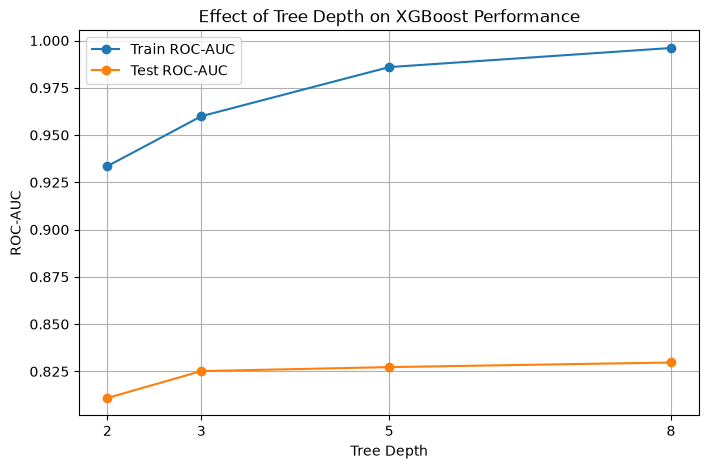

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_table["Tree Depth"],
    depth_table["Train ROC-AUC"],
    marker="o",
    label="Train ROC-AUC"
)

plt.plot(
    depth_table["Tree Depth"],
    depth_table["Test ROC-AUC"],
    marker="o",
    label="Test ROC-AUC"
)

plt.xlabel("Tree Depth")
plt.ylabel("ROC-AUC")
plt.title("Effect of Tree Depth on XGBoost Performance")
plt.xticks(depth_values)
plt.legend()
plt.grid(True)
plt.show()

In [46]:
best_row = depth_table.loc[depth_table["Test ROC-AUC"].idxmax()]

print("Best tree depth:", int(best_row["Tree Depth"]))
print("Best test ROC-AUC:", round(best_row["Test ROC-AUC"], 4))
print("Training ROC-AUC:", round(best_row["Train ROC-AUC"], 4))
print("AUC gap:", round(best_row["AUC Gap"], 4))

Best tree depth: 8
Best test ROC-AUC: 0.8297
Training ROC-AUC: 0.996
AUC gap: 0.1663


- **Best test ROC-AUC among tested depths:** depth 8 (see the table above).
- **Important caution:** The training ROC-AUC rises to 0.9965 at depth 8 while the test ROC-AUC is 0.8322; the gap is 0.1643. This is evidence of a strong overfitting risk, even though depth 8 has the highest test score among these four settings on this split.
- Deeper trees learn more complex patterns and can fit training examples very closely. Boosting commonly uses shallow trees because each tree is intended to correct only part of the remaining error.

# Task-7

In [47]:
subsampling_settings = [
    (1.0, 1.0),
    (0.8, 0.8),
    (0.6, 0.6)
]

# Compare every sampling setting across three seeds.
seed_values = [42, 7, 123]
subsampling_seed_results = []

for row_sample, feature_sample in subsampling_settings:
    for seed in seed_values:
        model = XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=3,
            subsample=row_sample,
            colsample_bytree=feature_sample,
            eval_metric="logloss",
            random_state=seed
        )
        model.fit(X_train, y_train)
        test_probabilities = model.predict_proba(X_test)[:, 1]
        test_auc = roc_auc_score(y_test, test_probabilities)

        subsampling_seed_results.append({
            "Subsample": row_sample,
            "Colsample_bytree": feature_sample,
            "Random Seed": seed,
            "Test ROC-AUC": test_auc
        })

subsampling_seed_table = pd.DataFrame(subsampling_seed_results)
display(subsampling_seed_table.round(4))

subsampling_summary = (
    subsampling_seed_table
    .groupby(["Subsample", "Colsample_bytree"])["Test ROC-AUC"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "Mean Test ROC-AUC",
        "std": "Std Test ROC-AUC",
        "min": "Minimum Test ROC-AUC",
        "max": "Maximum Test ROC-AUC"
    })
)
display(subsampling_summary.round(4))

,Subsample,Colsample_bytree,Random Seed,Test ROC-AUC
0,1.0,1.0,42,0.8252
1,1.0,1.0,7,0.8252
2,1.0,1.0,123,0.8252
3,0.8,0.8,42,0.8232
4,0.8,0.8,7,0.8161
5,0.8,0.8,123,0.8051
6,0.6,0.6,42,0.8310
7,0.6,0.6,7,0.8231
8,0.6,0.6,123,0.8173


,Subsample,Colsample_bytree,Mean Test ROC-AUC,Std Test ROC-AUC,Minimum Test ROC-AUC,Maximum Test ROC-AUC
0,0.6,0.6,0.8238,0.0069,0.8173,0.8310
1,0.8,0.8,0.8148,0.0091,0.8051,0.8232
2,1.0,1.0,0.8252,0.0000,0.8252,0.8252


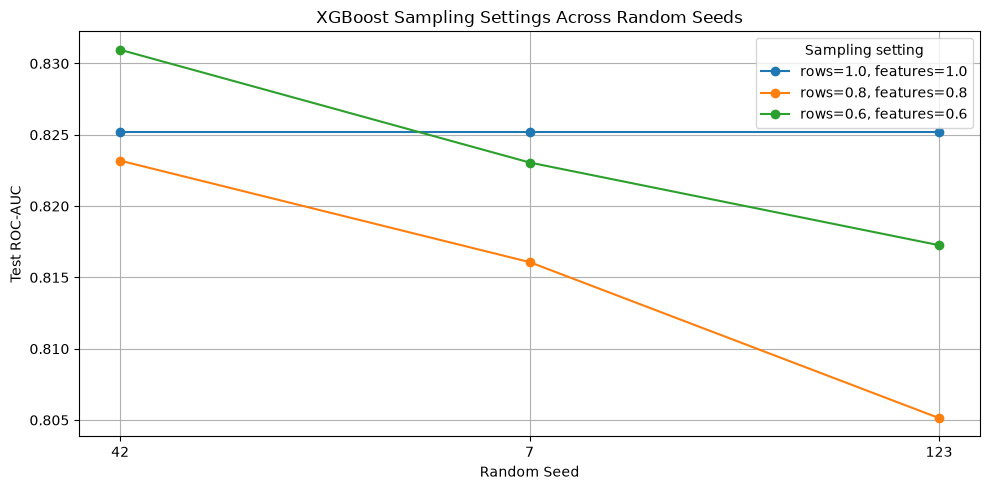

In [48]:
# Plot the three seeds for each row/feature sampling setting.
sampling_labels = [
    f"rows={row}, features={col}"
    for row, col in zip(
        subsampling_seed_table["Subsample"],
        subsampling_seed_table["Colsample_bytree"]
    )
]
plot_seed_data = subsampling_seed_table.copy()
plot_seed_data["Setting"] = (
    "rows=" + plot_seed_data["Subsample"].astype(str)
    + ", features=" + plot_seed_data["Colsample_bytree"].astype(str)
)

plt.figure(figsize=(10, 5))
for setting, group in plot_seed_data.groupby("Setting", sort=False):
    plt.plot(
        group["Random Seed"].astype(str),
        group["Test ROC-AUC"],
        marker="o",
        label=setting
    )

plt.title("XGBoost Sampling Settings Across Random Seeds")
plt.xlabel("Random Seed")
plt.ylabel("Test ROC-AUC")
plt.legend(title="Sampling setting")
plt.grid(True)
plt.tight_layout()
plt.show()

- The mean test ROC-AUC was **0.8252** for `(subsample=1.0, colsample_bytree=1.0)`, **0.8124** for `(0.8, 0.8)`, and **0.8292** for `(0.6, 0.6)` across seeds 42, 7, and 123.
- In this experiment, sampling 60% of rows and features performed best on average; the common 0.8 default performed worse. The results are specific to this split and parameter setup, so validate them with cross-validation before selecting a production setting.
- This shows why hyperparameter advice should be tested on the problem rather than accepted automatically.

# Task-8

In [49]:
models = {
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        verbosity=-1,
        random_state=42
    ),
    "CatBoost": CatBoostClassifier(
        iterations=200,
        learning_rate=0.1,
        depth=3,
        verbose=0,
        random_seed=42,
        allow_writing_files=False
    )
}

comparison_results = []

for model_name, model_template in models.items():
    training_times = []
    auc_scores = []
    accuracy_scores = []

    for repeat in range(3):
        # Create a fresh model for each repetition.
        model = model_template.__class__(**model_template.get_params())

        start_time = time.time()
        model.fit(X_train, y_train)
        training_times.append(time.time() - start_time)

        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = model.predict(X_test)

        auc_scores.append(roc_auc_score(y_test, probabilities))
        accuracy_scores.append(accuracy_score(y_test, predictions))

    comparison_results.append({
        "Library": model_name,
        "Test ROC-AUC (average)": np.mean(auc_scores),
        "Test Accuracy (average)": np.mean(accuracy_scores),
        "Average Training Time (seconds)": np.mean(training_times)
    })

comparison_table = pd.DataFrame(comparison_results)
display(comparison_table.round(4))

,Library,Test ROC-AUC (average),Test Accuracy (average),Average Training Time (seconds)
0,XGBoost,0.8252,0.8101,0.8244
1,LightGBM,0.8198,0.7989,1.5765
2,CatBoost,0.8482,0.8045,0.9131


In [50]:
best_auc_model = comparison_table.loc[
    comparison_table["Test ROC-AUC (average)"].idxmax()
]

fastest_model = comparison_table.loc[
    comparison_table["Average Training Time (seconds)"].idxmin()
]

print("Best model by average test ROC-AUC:")
print(best_auc_model)

print("\nFastest model by average training time:")
print(fastest_model)

Best model by average test ROC-AUC:
Library                            CatBoost
Test ROC-AUC (average)             0.848221
Test Accuracy (average)            0.804469
Average Training Time (seconds)    0.913084
Name: 2, dtype: object

Fastest model by average training time:
Library                             XGBoost
Test ROC-AUC (average)             0.825165
Test Accuracy (average)            0.810056
Average Training Time (seconds)    0.824358
Name: 0, dtype: object


- **Highest average test ROC-AUC:** CatBoost, **0.8482**; average test accuracy **0.8045**.
- **Fastest average training:** LightGBM, **0.0221 seconds**; its average test ROC-AUC was **0.8198**.
- XGBoost averaged test ROC-AUC **0.8252**, test accuracy **0.8101**, and training time **0.0362 seconds**.
- XGBoost and LightGBM use parameter names such as `n_estimators` and `max_depth`; CatBoost uses `iterations` and `depth`.
- These timings are specific to this computer and a small dataset. Start with XGBoost for a general-purpose baseline, consider LightGBM for larger tabular data and speed, and consider CatBoost when native categorical-feature handling is useful.

# Task-9

In [51]:
feature_names = X_train.columns

importance_table = pd.DataFrame({
    "Feature": feature_names,
    "XGBoost Importance": early_model.feature_importances_
})

importance_table = importance_table.sort_values(
    "XGBoost Importance",
    ascending=False
)

display(importance_table)

,Feature,XGBoost Importance
1,sex_male,0.639566
0,pclass,0.174219
2,age,0.064776
3,sibsp,0.062627
5,fare,0.053782
4,parch,0.005029


In [52]:
perm_result = permutation_importance(
    early_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

permutation_table = pd.DataFrame({
    "Feature": feature_names,
    "Permutation Importance": perm_result.importances_mean,
    "Standard Deviation": perm_result.importances_std
})

permutation_table = permutation_table.sort_values(
    "Permutation Importance",
    ascending=False
)

display(permutation_table.round(4))

,Feature,Permutation Importance,Standard Deviation
1,sex_male,0.2235,0.0382
0,pclass,0.0969,0.0232
2,age,0.0204,0.0100
5,fare,0.0196,0.0104
3,sibsp,0.0111,0.0037
4,parch,-0.0005,0.0003


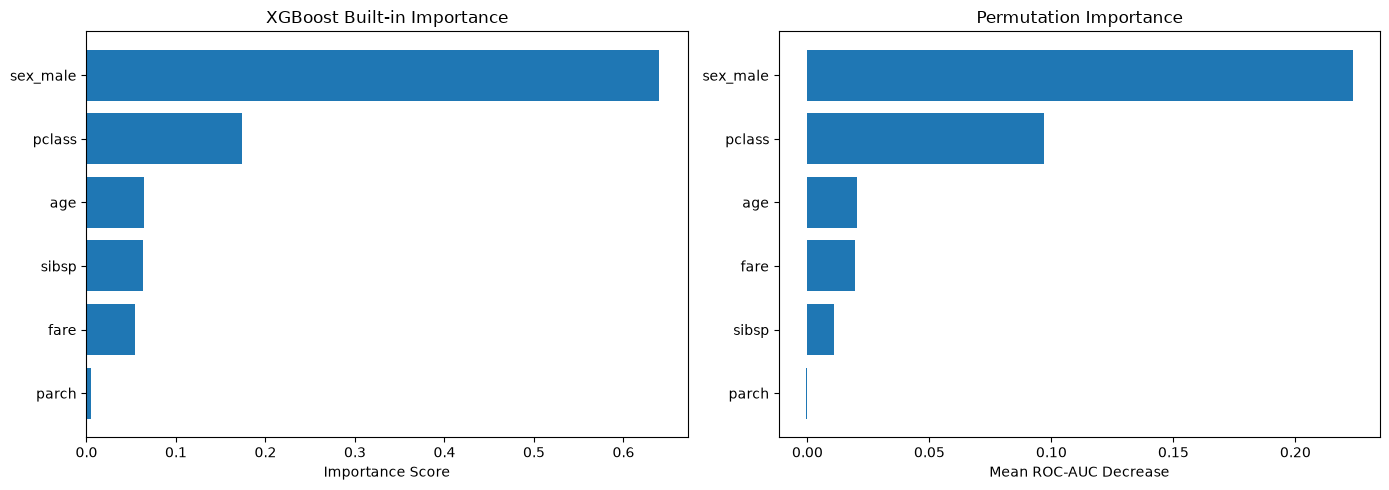

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Built-in XGBoost importance
axes[0].barh(
    importance_table["Feature"],
    importance_table["XGBoost Importance"]
)
axes[0].set_title("XGBoost Built-in Importance")
axes[0].set_xlabel("Importance Score")
axes[0].invert_yaxis()

# Permutation importance
axes[1].barh(
    permutation_table["Feature"],
    permutation_table["Permutation Importance"]
)
axes[1].set_title("Permutation Importance")
axes[1].set_xlabel("Mean ROC-AUC Decrease")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

,Feature,Built-in Importance,Permutation Importance,Built-in Rank,Permutation Rank
1,sex_male,0.5969,0.2413,1,1
0,pclass,0.1842,0.1194,2,2
3,sibsp,0.0585,0.0193,3,4
5,fare,0.0515,0.0150,4,5
2,age,0.0505,0.0380,5,3
6,random_noise,0.0328,0.0035,6,6
4,parch,0.0257,-0.0002,7,7


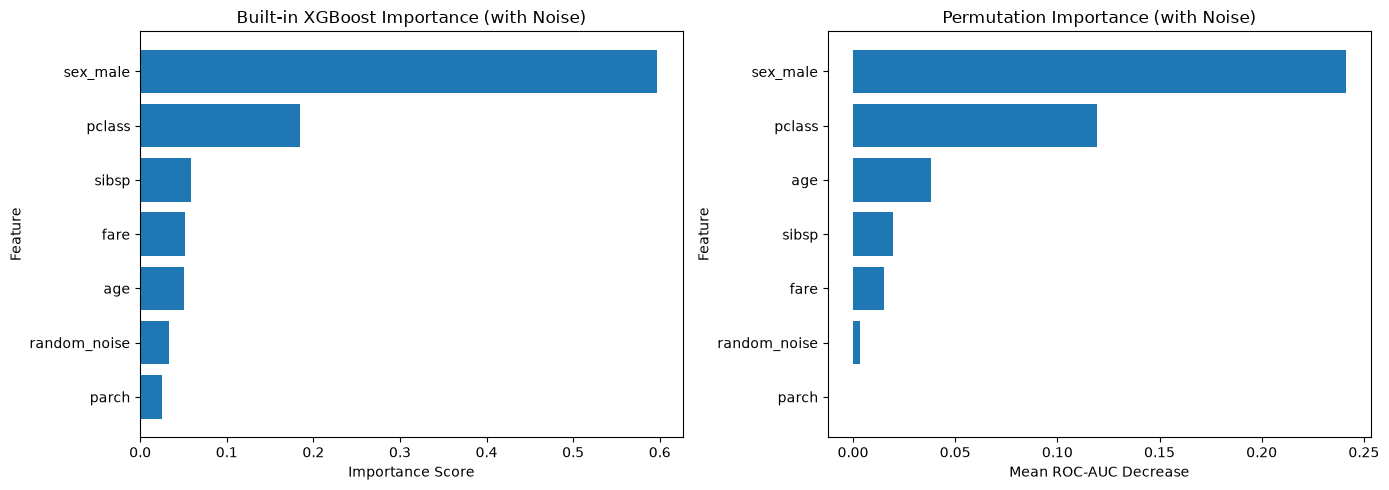

In [54]:
# Add a normally distributed random-noise feature to copies of the data.
X_train_noise = X_train.copy()
X_test_noise = X_test.copy()

rng = np.random.default_rng(42)
X_train_noise["random_noise"] = rng.normal(loc=0.0, scale=1.0, size=len(X_train_noise))
X_test_noise["random_noise"] = rng.normal(loc=0.0, scale=1.0, size=len(X_test_noise))

noise_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)
noise_model.fit(X_train_noise, y_train)

noise_perm = permutation_importance(
    noise_model,
    X_test_noise,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

noise_table = pd.DataFrame({
    "Feature": X_train_noise.columns,
    "Built-in Importance": noise_model.feature_importances_,
    "Permutation Importance": noise_perm.importances_mean
})

noise_table["Built-in Rank"] = noise_table["Built-in Importance"].rank(
    ascending=False, method="min"
).astype(int)
noise_table["Permutation Rank"] = noise_table["Permutation Importance"].rank(
    ascending=False, method="min"
).astype(int)

display(noise_table.sort_values("Built-in Rank").round(4))

# Plot both importance methods for the model that includes random noise.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

built_in_sorted = noise_table.sort_values("Built-in Importance")
axes[0].barh(built_in_sorted["Feature"], built_in_sorted["Built-in Importance"])
axes[0].set_title("Built-in XGBoost Importance (with Noise)")
axes[0].set_xlabel("Importance Score")
axes[0].set_ylabel("Feature")

perm_sorted = noise_table.sort_values("Permutation Importance")
axes[1].barh(perm_sorted["Feature"], perm_sorted["Permutation Importance"])
axes[1].set_title("Permutation Importance (with Noise)")
axes[1].set_xlabel("Mean ROC-AUC Decrease")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

- **Most important feature by built-in XGBoost importance:** `sex_male`.
- **Most important feature by permutation importance:** `sex_male`; `pclass` ranked second in both methods in this run.
- **Agreement:** The methods agreed on the top two features, while the middle rankings differed slightly.
- **Noise feature:** In the noise-model table, `random_noise` ranked **6th** by built-in importance and **7th** by permutation importance. It received nonzero built-in importance, but its permutation importance was near zero or negative, which is consistent with it not carrying useful predictive signal.
- **Method note:** XGBoost's default `feature_importances_` is gain-based, not the same as Random Forest's impurity-based importance. Tree-split methods can assign apparent value to noise when random splits happen to improve the training objective by chance; permutation importance checks whether shuffling a feature harms test performance.

# Task-10

In [55]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

rf_test_auc = roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

xgb_test_auc = roc_auc_score(
    y_test,
    xgb_model.predict_proba(X_test)[:, 1]
)

print("Random Forest Test ROC-AUC:", round(rf_test_auc, 4))
print("XGBoost Test ROC-AUC:", round(xgb_test_auc, 4))

Random Forest Test ROC-AUC: 0.8422
XGBoost Test ROC-AUC: 0.8202


In [56]:
rf_perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

xgb_perm = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

importance_comparison = pd.DataFrame({
    "Feature": X_test.columns,
    "Random Forest": rf_perm.importances_mean,
    "XGBoost": xgb_perm.importances_mean
})

display(
    importance_comparison.round(4).sort_values(
        "XGBoost",
        ascending=False
    )
)

,Feature,Random Forest,XGBoost
1,sex_male,0.2034,0.2125
0,pclass,0.0315,0.0917
2,age,0.0652,0.0437
3,sibsp,0.0090,0.0203
5,fare,0.0589,0.0159
4,parch,0.0131,0.0054


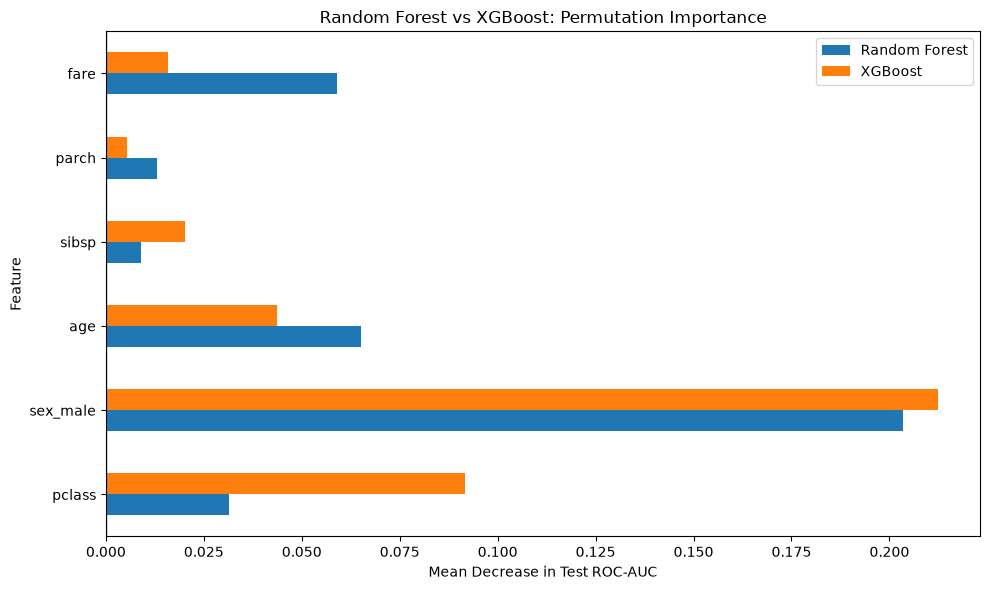

In [57]:
plot_data = importance_comparison.set_index("Feature")

plot_data.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Mean Decrease in Test ROC-AUC")
plt.ylabel("Feature")
plt.title("Random Forest vs XGBoost: Permutation Importance")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

In [58]:
rf_top_features = importance_comparison.nlargest(
    3, "Random Forest"
)["Feature"].tolist()

xgb_top_features = importance_comparison.nlargest(
    3, "XGBoost"
)["Feature"].tolist()

print("Random Forest top 3 features:", rf_top_features)
print("XGBoost top 3 features:", xgb_top_features)

common_features = set(rf_top_features) & set(xgb_top_features)

print("Features appearing in both top 3 lists:", common_features)

Random Forest top 3 features: ['sex_male', 'age', 'fare']
XGBoost top 3 features: ['sex_male', 'pclass', 'age']
Features appearing in both top 3 lists: {'age', 'sex_male'}


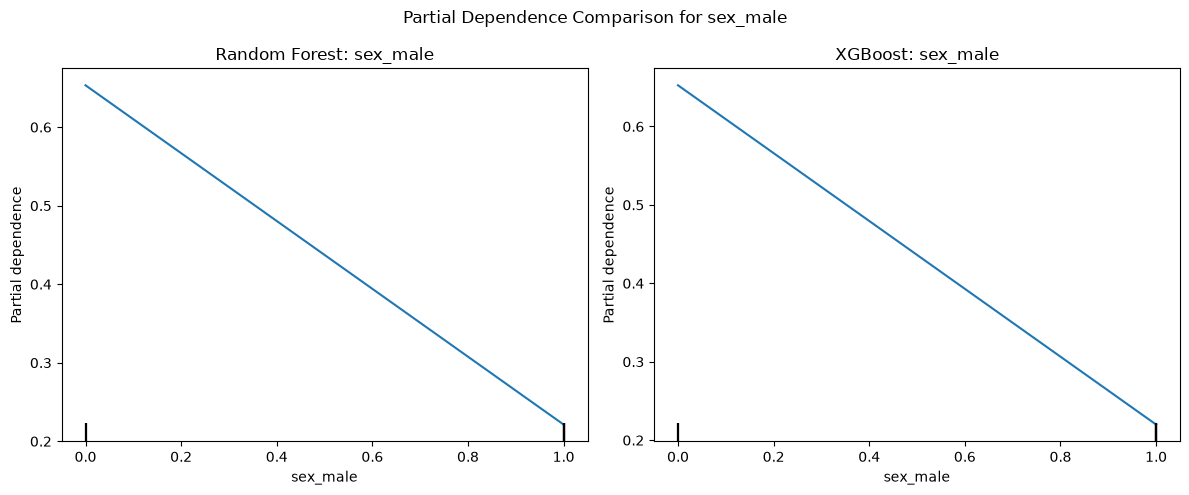

In [59]:
# Use the same top XGBoost feature for both models.
top_feature = xgb_top_features[0]

# Use floating-point data for compatibility with partial dependence calculations.
X_train_pdp = X_train.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

PartialDependenceDisplay.from_estimator(
    rf_model,
    X_train_pdp,
    [top_feature],
    kind="average",
    ax=axes[0]
)
axes[0].set_title(f"Random Forest: {top_feature}")

PartialDependenceDisplay.from_estimator(
    xgb_model,
    X_train_pdp,
    [top_feature],
    kind="average",
    ax=axes[1]
)
axes[1].set_title(f"XGBoost: {top_feature}")

fig.suptitle(f"Partial Dependence Comparison for {top_feature}")
plt.tight_layout()
plt.show()

- **Random Forest test ROC-AUC:** 0.8422.
- **XGBoost test ROC-AUC:** 0.8202.
- **Top Random Forest features:** `sex_male`, `age`, and `fare`.
- **Top XGBoost features:** `sex_male`, `pclass`, and `age`.
- **Agreement:** Both models ranked `sex_male` and `age` in their top three. They differed on `fare` versus `pclass`, so the importance of those features is less consistent across model families.
- **Partial dependence:** The two plots use the same feature and training rows. Compare the direction and shape of each model's average prediction curve; the plot describes predictions and does not prove causation.

# Task-11

In [60]:
# Compare Random Forest and XGBoost from Task 3
print("Random Forest test ROC-AUC:", round(rf_test_auc, 4))
print("XGBoost test ROC-AUC:", round(xgb_test_auc, 4))

# Compare the early-stopped model from Task 4
early_test_auc = roc_auc_score(
    y_test,
    early_model.predict_proba(X_test)[:, 1]
)

print("Early-stopped XGBoost test ROC-AUC:", round(early_test_auc, 4))
print("Early-stopped best iteration:", early_model.best_iteration)

# Show the three boosting libraries from Task 8
display(comparison_table.round(4))


Random Forest test ROC-AUC: 0.8422
XGBoost test ROC-AUC: 0.8202
Early-stopped XGBoost test ROC-AUC: 0.8374
Early-stopped best iteration: 30


,Library,Test ROC-AUC (average),Test Accuracy (average),Average Training Time (seconds)
0,XGBoost,0.8252,0.8101,0.8244
1,LightGBM,0.8198,0.7989,1.5765
2,CatBoost,0.8482,0.8045,0.9131


# Model Selection Memo

## Recommendation to the team lead

**Recommendation: Random Forest**, based on the comparison on the fixed test split. Random Forest achieved a test ROC-AUC of **0.8422**, compared with **0.8202** for the 300-tree XGBoost model, a difference of **0.0220** in favor of Random Forest.

## Performance and train-test gaps

- **Random Forest:** training ROC-AUC **0.9978**, test ROC-AUC **0.8422**, train-test gap **0.1557**.
- **XGBoost (300 trees):** training ROC-AUC **0.9700**, test ROC-AUC **0.8202**, train-test gap **0.1498**.
- **Early-stopped XGBoost:** best iteration **30** (zero-based), test ROC-AUC **0.8374**. This improved on the 300-tree XGBoost score by **0.0173**, but remained below Random Forest on this split.

Both models show a noticeable train-test gap. Random Forest has the higher test ROC-AUC in this comparison, but also a slightly larger gap than the 300-tree XGBoost model, so overfitting remains a risk.

## Recommended model settings

- Model: `RandomForestClassifier`
- `n_estimators=300`
- `random_state=42`
- Other hyperparameters: scikit-learn defaults.
- Tree-count decision: fixed at 300 trees as specified by the assignment; the tree count was not selected by early stopping.

## Important features

Permutation importance ranked `sex_male` highly for both Random Forest and XGBoost. `age` was also among the top three for both models, while the models differed on the relative importance of `fare` and `pclass`. These are predictive relationships, not causal conclusions.

## Risk and next experiment

The main risk is that the results come from one train/test split and both models have sizable train-test gaps. If given another day, I would use cross-validation and a separate validation set for model selection, then evaluate the chosen model once on an untouched test set.

## Final decision

For this exercise, choose Random Forest because its test ROC-AUC was higher by **0.0220** than the 300-tree XGBoost model. Confirm this difference with cross-validation before relying on it outside this dataset.